Setup and simulation for A = 0.8, omega = 1

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.titlesize": 20,
})

folder = Path.cwd()
if not (folder / "harmonic.py").exists():
    folder = folder.parent

sys.path.insert(0, str(folder))

from harmonic import HarmonicOscillator

def simulate(A=0.8, omega=1.0, dt=0.02, n=128, L=12, tmax=20):
    ho = HarmonicOscillator(boundary=(-L, L), n=n)
    x = ho.xi()
    times = np.linspace(0, tmax, int(np.ceil(tmax / dt)) + 1)

    energies, basis = ho.eigenstates()

    states = np.empty((len(times), n), dtype=complex)
    states[0] = basis[:, 0]

    for i in range(1, len(times)):
        # Use your class to evolve over this time interval
        U_step = ho.time_evolution(
            [times[i]],
            omega=omega,
            A=A,
            t0=times[i-1]
        )

        states[i] = U_step @ states[i-1]

    # <H0>: sum each eigenstate's energy × its population
    amplitudes = states @ basis.conj()
    E0 = np.abs(amplitudes)**2 @ energies

    return x, times, states, E0

Check convergence for A = 0.8, omega = 1

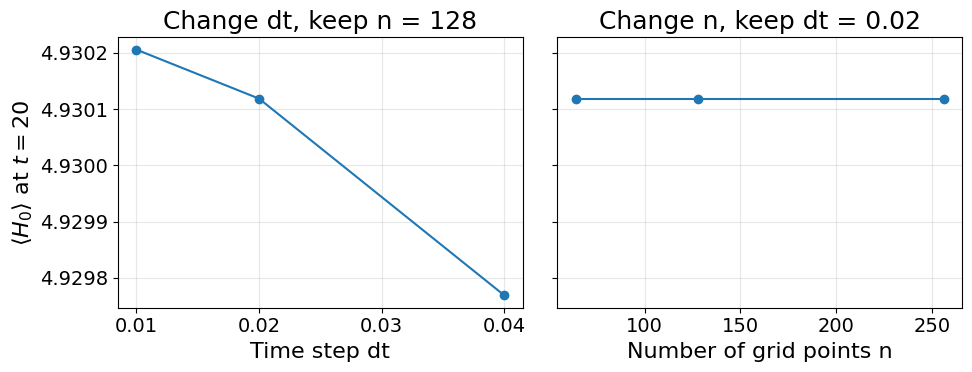

In [15]:
dt_values = sorted(time_results)
n_values = sorted(grid_results)

# Energy at t = 20 for each parameter choice
energy_dt = [time_results[dt][-1] for dt in dt_values]
energy_n = [grid_results[n][-1] for n in n_values]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

axes[0].plot(dt_values, energy_dt, "o-")
axes[0].set_xlabel("Time step dt")
axes[0].set_title("Change dt, keep n = 128")

axes[1].plot(n_values, energy_n, "o-")
axes[1].set_xlabel("Number of grid points n")
axes[1].set_title("Change n, keep dt = 0.02")

axes[0].set_ylabel(r"$\langle H_0\rangle$ at $t=20$")

for ax in axes:
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

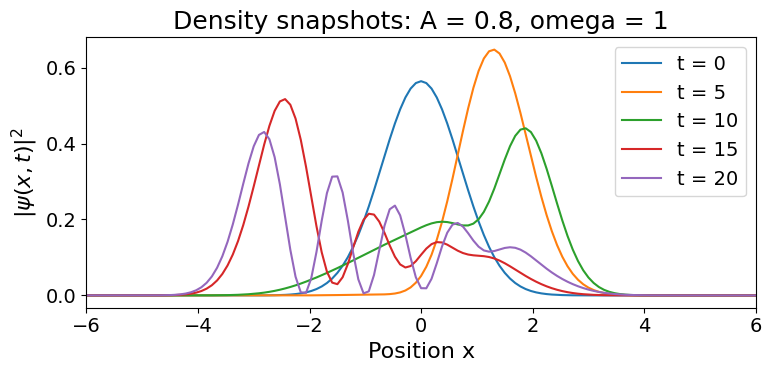

In [16]:
# More spatial points give smoother density plots
x, times, states, _ = simulate(A=0.8, omega=1.0, n=256)
dx = x[1] - x[0]

plt.figure(figsize=(8, 4))

for timestamp in [0, 5, 10, 15, 20]:
    i = np.argmin(np.abs(times - timestamp))
    density = np.abs(states[i])**2 / dx
    plt.plot(x, density, label=f"t = {times[i]:g}")

plt.xlim(-6, 6)
plt.xlabel("Position x")
plt.ylabel(r"$|\psi(x,t)|^2$")
plt.title("Density snapshots: A = 0.8, omega = 1")
plt.legend()
plt.tight_layout()
plt.show()

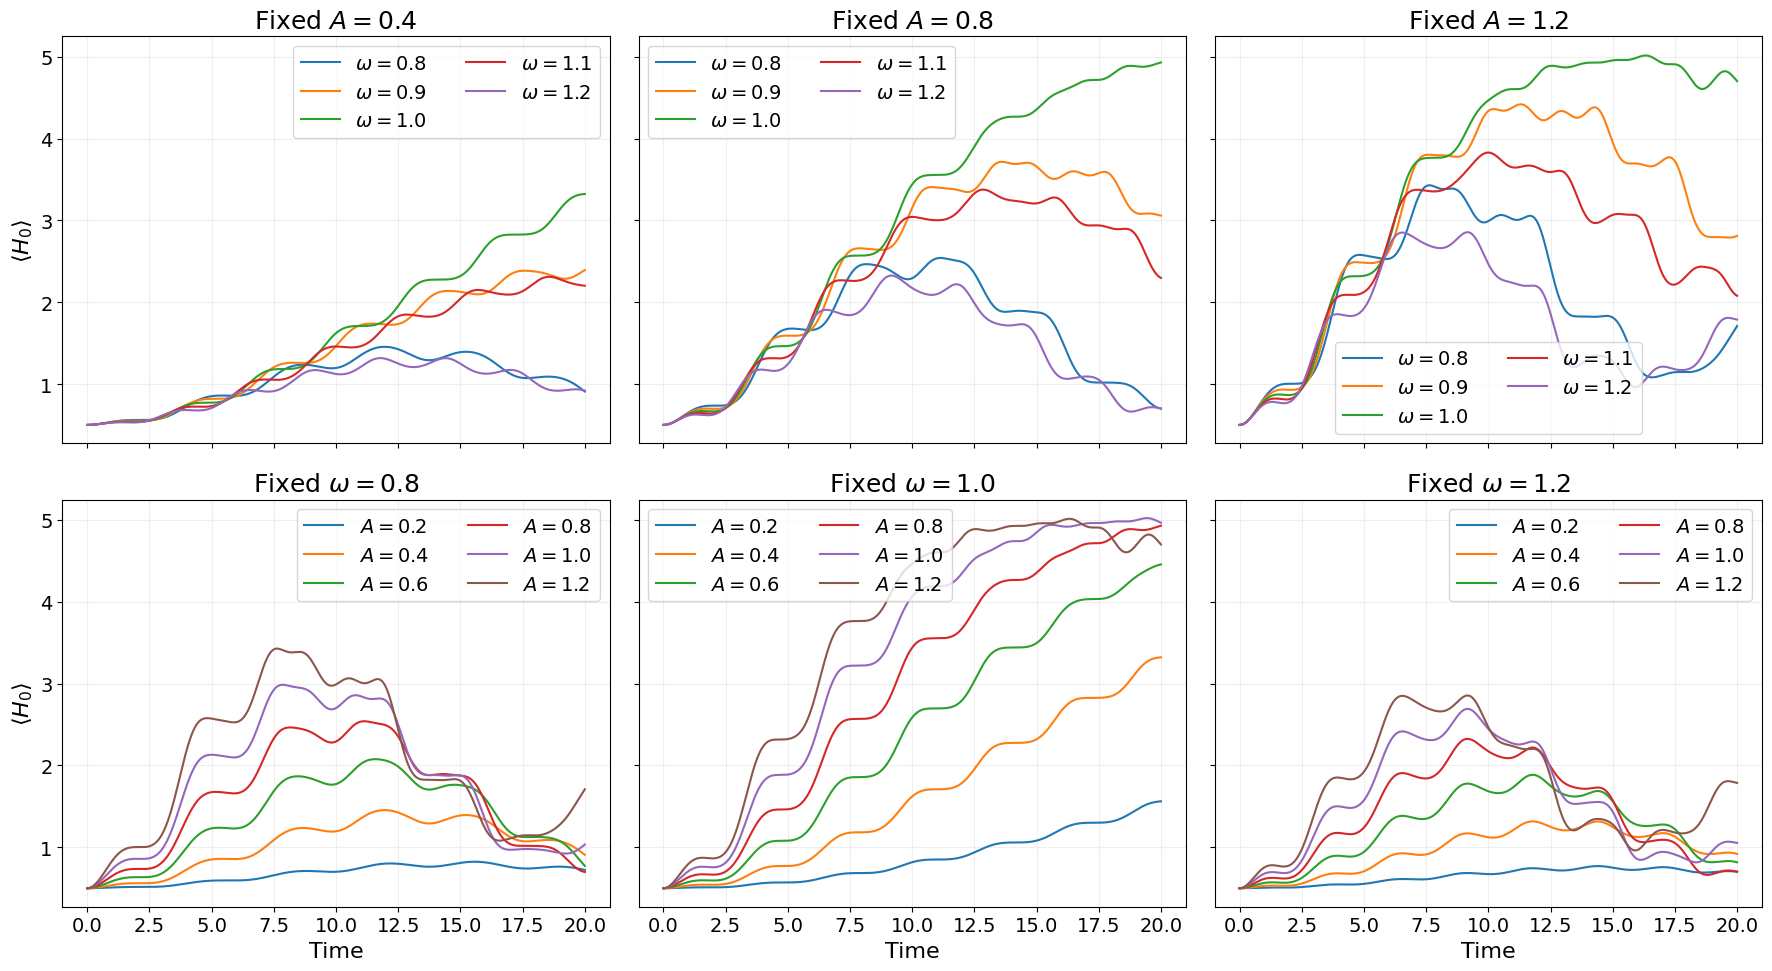

In [18]:
A_panels = [0.4, 0.8, 1.2]
A_curves = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]

omega_panels = [0.8, 1.0, 1.2]
omega_curves = [0.8, 0.9, 1.0, 1.1, 1.2]

tmax = 20

fig, axes = plt.subplots(
    2, 3, figsize=(18, 10),
    sharex=True, sharey=True
)

# Top row: fix A, vary omega
for ax, A in zip(axes[0], A_panels):
    for omega in omega_curves:
        _, t, _, energy = simulate(A=A, omega=omega, tmax=tmax)
        ax.plot(t, energy, label=rf"$\omega={omega:.1f}$")

    ax.set_title(rf"Fixed $A={A:.1f}$")

# Bottom row: fix omega, vary A
for ax, omega in zip(axes[1], omega_panels):
    for A in A_curves:
        _, t, _, energy = simulate(A=A, omega=omega, tmax=tmax)
        ax.plot(t, energy, label=rf"$A={A:.1f}$")

    ax.set_title(rf"Fixed $\omega={omega:.1f}$")
    ax.set_xlabel("Time")

for ax in axes[:, 0]:
    ax.set_ylabel(r"$\langle H_0\rangle$")

for ax in axes.flat:
    ax.legend(ncol=2)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()